# Welcome to the ACPE 2026: NLP Coding Lab!

This notebook provides a hands-on introduction to Natural Language Processing (NLP) using Python, `spaCy`, and `medspaCy`. We'll explore fundamental NLP concepts and then dive into advanced techniques for medical text analysis.

Author: Crystal Leung

Collaborated with: Ting Xia, Yanmin Zhu, Harvey Koh, Richeek Prahdan

## Notebook Sections Walkthrough

This lab is structured into three main sections:

1.  **Section 1: NLP Basics**: Here, we'll cover foundational NLP concepts such as tokenization, lemmatization, stopword removal, and Part-of-Speech (POS) tagging. These are essential preprocessing steps for any text analysis task.

2.  **Section 2: Named Entity Recognition (NER) with `medspaCy`**: This section introduces `medspaCy`, a powerful library for clinical NLP. You'll learn how to define custom medical entities using `TargetRule`s and extract them from clinical notes, understanding important contextual attributes like negation and uncertainty.

3.  **Section 3: Using extracted entities for prediction**: Finally, we'll take the entities extracted in the previous section and use them to build a simple machine learning model. This involves converting text entities into numerical representations (Bag-of-Words and TF-IDF) and training a logistic regression model to make predictions based on clinical text.

# Section 1: NLP Basics

This section uses the package spacy, which is an open-source library for advanced Natural Language Processing (NLP) in Python.

Refer to https://spacy.io/ for more details

Code reference: https://spacy.io/usage/linguistic-features#named-entities

In [ ]:
# Install required package
!pip install -U spacy

In [ ]:
import spacy
import pandas as pd

nlp = spacy.load("en_core_web_sm")

### Step 1: Tokenisation

Tokenisation is a preprocessing step that splits text into smaller parts such as words or sentences.

By dividing text into smaller parts, it enables more efficient text analysis and helps with more complex NLP tasks such as named entity recognition (NER) and feature inputs into downstream tasks such as machine learning classifications.

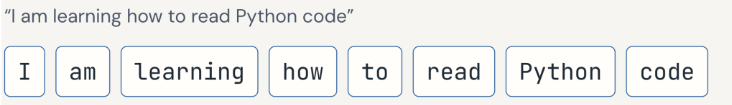



In [ ]:
# Step 1: Tokenisation
exmp1 = nlp("Tokenisation is an important step in NLP. It is splits text into smaller parts such as words or sentences.")

words = [token.text for token in exmp1]
sentences = [sent.text for sent in exmp1.sents]

print("Word Tokens:", words)
print("Sentence Tokens:", sentences)

### Step 2: Lemmatisation

Lemmatisation transforms the words into its root form (known as a lemma) by standardising the text.

Example: ``` running, ran, runs --> run ```

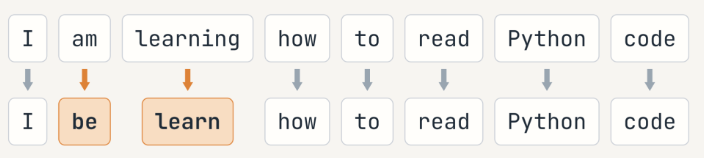


In [ ]:
# Step 2: Lemmatisation
exmp2 = nlp("Lemmatisation reduces the words into its root form.")

lemmas = [token.lemma_ for token in exmp2]

print("Lemmatized form:", lemmas)

### Step 3: Removing stopwords

**What are stopwords?**
Stopwords are everyday connective words (e.g. the, is, at, not) that build sentences but carry little unique information by themselves.

**Why do we remove them?**
Stopwords are often removed to reduce number of words processsed, particularly if there are limited memory and processing capabilities.

**When should we keep them?**
With more modern models like BERT, we usually keep these stopwords, as they are capable of reading full sentences and understand the surrounding contexts. Removing small words like ```"not", "never"``` can affect the model's understanding of the meaning and affect its performance [1].

*Reference:
Qiao, Y., Xiong, C., Liu, Z., & Liu, Z. (2019). Understanding the Behaviors of BERT in Ranking (1904.07531v4). arXiv. https://arxiv.org/abs/1904.07531v4*

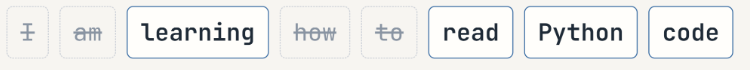

In [ ]:
# Step 3: Removing stop words
exmp3 = nlp("Stop words are frequent words that appear in text but do not hold any meaning when conducting some NLP texts. These include words such as 'and', 'are'")

filtered_words = [token.text for token in exmp3 if not token.is_stop]
print("Filtered Words:", filtered_words)

### Step 4: POS Tagging

**What are POS tags?**
The grammatical category of each word based on its context and meaning.

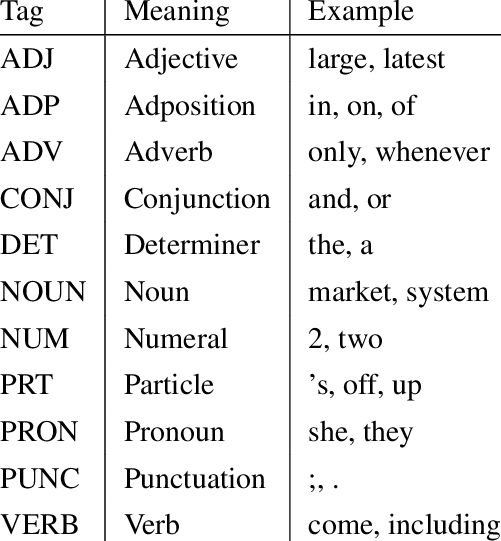

Ghader, H. (2021). An empirical analysis of phrase-based and neural machine translation. arXiv preprint arXiv:2103.03108.

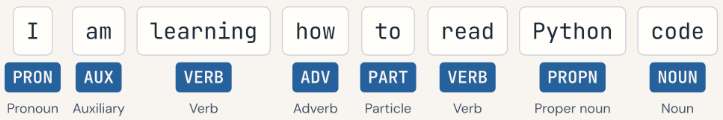

In [ ]:
exmp4 = nlp("Now you know the basics of NLP.")

for token in exmp4:
    print(token.text, "=>", token.pos_)

# Section 2: Named Entity Recognition

**What is named entity recognition?** Named entity recognition (NER) is an NLP technique that identifies and classifiers names and concepts from text. It is commonly used in medical research to identify drug names, symptoms and more.

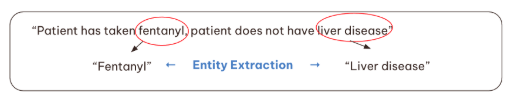



The code below is adapted from Feller, D. (2022, September 16). Easy Medical NLP in Python using the medspaCy library. Medium. https://medium.com/@danieljfeller/easy-medical-nlp-in-python-using-the-medspacy-library-4753f4806b6c



Often we will link it to existing biomedical ontologies such as [UMLS](https://www.nlm.nih.gov/research/umls/index.html) or [SNOMED-CT](https://www.nlm.nih.gov/healthit/snomedct/index.html). However, these require a license, and we won't be able to use them in this tutorial.


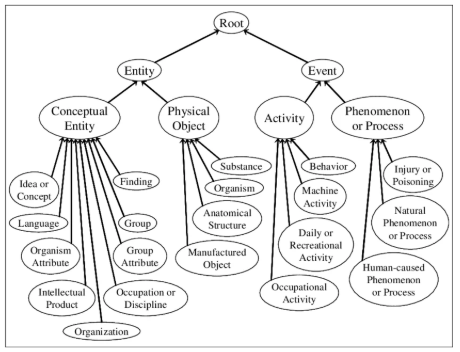
Sidhu, Amandeep. (2013). Biomedical Ontologies.


Other NLP Tools:

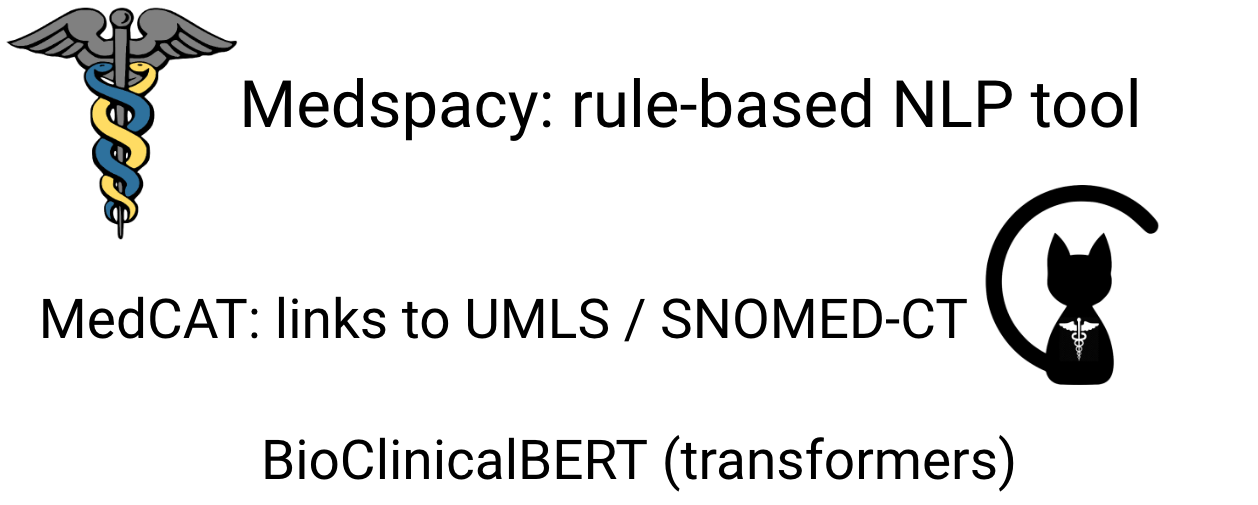

### Using `medspaCy` for Custom Named Entity Recognition (NER)

`medspaCy` extends `spaCy`'s capabilities for clinical text. A core feature is the `TargetRule`, which allows us to define custom entities and their corresponding labels that `medspaCy` will identify in text. This is particularly useful for domain-specific NER tasks where standard `spaCy` models might not have pre-trained entities relevant to medical or clinical contexts.

In this section, we will demonstrate how to define `TargetRule` for medical terms (e.g., DRUGS, DISEASES, SYMPTOMS) and use `medspaCy` to extract these custom entities from clinical text. This approach enables us to build a tailored NER system without extensive training data, relying on a rule-based methodology.

#### Capability 1: `TargetRule()` → entity extraction
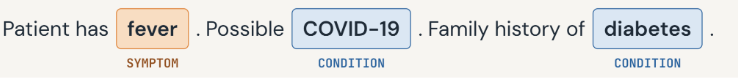


####Capability 2: Contextualisation

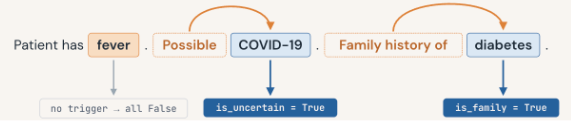


### Define our research question

**Task: Classify opioid case**

Definition: opioid case are cases opioids ***contributed*** to the presentation; they can include opioid overdoses, opioids taken, multiple drugs taken included opioids, suspected opioid overdoses

Example:

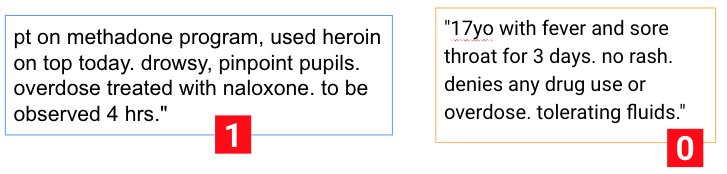


### Challenges of real world data

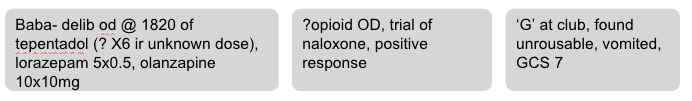

In [ ]:
import sys
# Install medspacy
!{sys.executable} -m pip install medspacy
print("MedSpaCy installed successfully.")

In [ ]:
# Load libraries
import spacy
import medspacy
import pandas as pd
from medspacy.target_matcher import TargetRule

# This turns off loguru messages coming from PyRuSH only.
from loguru import logger
logger.disable("PyRuSH")

In [ ]:
# Load the medspacy pipeline
nlp_med = medspacy.load()

# Get the existing TargetMatcher from the pipeline
target_matcher = nlp_med.get_pipe("medspacy_target_matcher")

# Define medical terms to match and their labels
rules = [
    TargetRule("opioid", "DRUG"),
    TargetRule("fentanyl", "DRUG"),
    TargetRule("methadone", "DRUG"),
    TargetRule("benzodiazepines", "DRUG"),
    TargetRule("COVID-19", "DIAGNOSIS"),
    TargetRule("diabetes", "DIAGNOSIS"),
    TargetRule("fever", "SYMPTOM"),
    TargetRule("headache", "SYMPTOM"),
    TargetRule("drowsy", "SYMPTOM"),
    TargetRule("pinpoint pupils", "SYMPTOM"),
    TargetRule("respiratory depression", "SYMPTOM"),
]
target_matcher.add(rules)

In [ ]:
med_exmp1 = """Patient has fever. Possible COVID-19. Family history of diabetes."""

doc_med = nlp_med(med_exmp1)

for ent in doc_med.ents:
    print(ent.text, ent.label_)

#### Contextualisation  

They all return TRUE/FALSE.

*   ```is_negated``` TRUE if ruled out
*   ```is_uncertain``` TRUE if not confirmed
* ```is_hypothetical``` TRUE if might happen
* ``` is_historical``` TRUE if in the past
* ```is_family``` TRUE if occured to family
>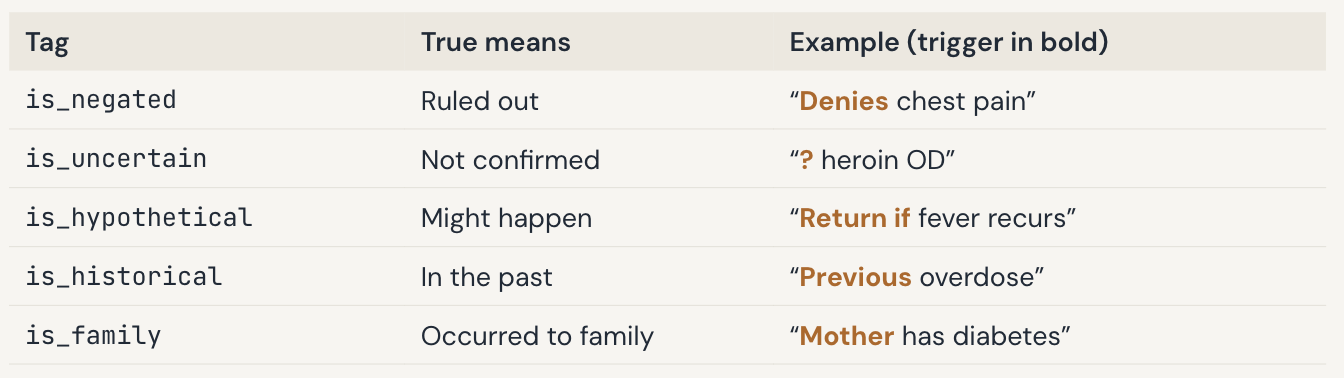

In [ ]:
med_exmp1 = """Patient has fever. Possible COVID-19. Family history of diabetes."""

doc_med = nlp_med(med_exmp1)

# Extract medical entities into a DataFrame
med_ent_data = []
for ent in doc_med.ents:
    med_ent_data.append({
        'text': ent.text,
        'start_char': ent.start_char,
        'end_char': ent.end_char,
        'label': ent.label_,
        # add contexutalisation tags here
        "is_negated":      ent._.is_negated,
        "is_uncertain":    ent._.is_uncertain,
        "is_hypothetical": ent._.is_hypothetical,
        "is_historical":   ent._.is_historical,
        "is_family":       ent._.is_family,
    })

med_ent_df = pd.DataFrame(med_ent_data)

print("Medical Entities extracted using MedSpaCy:")
print(med_ent_df)

#### Exercise.. Do it yourself!

There are some words (entities) that we are interested in example 2, but we didn't include them in our target rule. Let's identify the entities of interest and update the TargetRule.


In [ ]:
med_exmp2 = """Pt BIBA after suspected heroin OD. History of opioid overdose.
               Naloxone given by paramedics.
               Presented with dizziness. Denies chest pain.
               She has a history of hypertension and diabetes."""

In [ ]:
# Step 1: Let's check what we already have in our TargetRule
for r in target_matcher.rules:
  print(r.literal, "|", r.category)

In [ ]:
# Step 2: Add your rules
# Format: TargetRule("term", "LABEL")
# Fill in within the "___" spaces
rules = [
    # Drugs
    TargetRule("___", "DRUG"),
    TargetRule("___", "DRUG"),

    # Symptoms
    TargetRule("___", "SYMPTOM"),
    TargetRule("___", "SYMPTOM"),

    # Diagnosis
    TargetRule("___", "DIAGNOSIS"),
    TargetRule("___", "DIAGNOSIS"),

    # Discussion: what about abbreviations like OD?
]

# Add rules
target_matcher.add(rules)

In [ ]:
# Step 3: Check whether the add was successful
for r in target_matcher.rules:
  print(r.literal, "|", r.category)

See solution below.

In [ ]:
# Add your rules
# Format: TargetRule("term", "LABEL")
# Fill in within the "___" spaces
rules = [
    # Drugs
    TargetRule("heroin", "DRUG"),
    TargetRule("naloxone", "DRUG"),

    # Symptoms
    TargetRule("dizziness", "SYMPTOM"),
    TargetRule("chest pain", "SYMPTOM"),

    # Diagnosis
    TargetRule("overdose", "DIAGNOSIS"),
    TargetRule("hypertension", "DIAGNOSIS"),

    # Discussion: what about abbreviations like OD?
]

# Add rules
target_matcher.add(rules)

# Section 3: Prediction model

In section 2, medspaCy found medical terms in clinical notes and checked their surrounding contextx. In this section, we will use those results to make a prediction.

Machine learning models cannot read text. They read numbers. So we:
1. Extract entities from each note with medspaCy.
2. Turn the entities into numbers (Bag-of-words or TF-IDF).
3. Train a simple model to predict whether the note describes an opioid-related case.

*The notes below are generated by Claude Opus 5.5.*

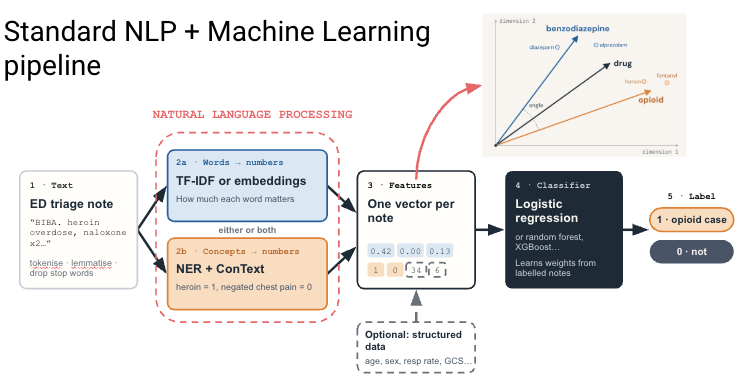

#### Common abbreviations

hx = history | COVID-19 = coronavirus disease 2019 | RAT = rapid antigen test | sats = oxygen saturation | RA = room air | BIBA = brought in by ambulance | CPR = cardiopulmonary resuscitation | pt = patient | c/o = complains of | SW = social work | x2 = times two (number of doses) | approx = approximately | hr / hrs = hour / hours | resp rate / RR = respiratory rate | mcg = microgram | IM = intramuscular | GCS = Glasgow Coma Scale | CT = computed tomography | neuro obs = neurological observations | LOC = loss of consciousness | BP = blood pressure | BGL = blood glucose level | L = left | ECG = electrocardiogram | 45M = 45-year-old male | ED = emergency department | obs = observations | SOB = shortness of breath | 30F = 30-year-old female | ? = query / suspected (e.g. ?intentional) | MH = mental health | 17yo = 17-year-old | IVDU = intravenous drug user

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Sample notes (1 = opioid case, 0 = not)
notes = [
    ("3 day hx of fever, dry cough and headache. COVID-19 positive on RAT this morning. sats 96% RA, tolerating fluids. no chest pain.", 0),
    ("BIBA from street. heroin overdose, bystander CPR not required. naloxone x2 doses. pt now alert, c/o dizziness and nausea, wants to self discharge. SW referral made.", 1),
    ("pt BIBA, found unresponsive in bathroom by friend, used heroin approx 1hr prior as per friend. resp rate 6 on arrival, naloxone 400mcg IM given by paramedics with good response. now GCS 14, c/o headache. no chest pain.", 1),
    ("presents with severe headache, worst of her life, sudden onset while at gym. hx of hypertension. CT head ordered, neuro obs.", 0),
    ("pt c/o dizziness after standing up quickly at work, no LOC. denies overdose or drug use. hx of hypertension, recently started new BP tablet.", 0),
    ("friend called ambulance after pt stopped breathing following heroin use. naloxone given x1 with rapid improvement. c/o dizziness on standing, no fever.", 1),
    ("pt with known diabetes presents with dizziness and sweating, BGL 2.8 on arrival. treated with glucose, improved. no chest pain.", 0),
    ("pt took extra opioid pain tabs for back pain over the weekend, family found him very sleepy and slow breathing. overdose suspected by family, confirmed by treating team. naloxone infusion started.", 1),
    ("elderly pt with diabetes, confused and hard to wake. extra opioid patches found on skin by paramedics. treated as overdose, naloxone given, BGL normal.", 1),
    ("pt presents with central chest pain radiating to L arm since this morning. hx of hypertension and diabetes. denies heroin use. ECG done, troponin pending.", 0),
    ("migraine type headache for 6 hrs, photophobia, no fever. usual meds not helping. no history of overdose. analgesia given.", 0),
    ("45M presented after overdose of opioid tablets with alcohol, amount unknown. pt drowsy but rousable. naloxone given in ED. obs stable, denies chest pain.", 1),
    ("fever and body aches for 2 days, household contact with COVID-19. denies opioid use. no chest pain, no SOB.", 0),
    ("pt on methadone program, used heroin on top today. drowsy, pinpoint pupils. overdose treated with naloxone. to be observed 4 hrs.", 1),
    ("30F, overdose of benzodiazepines and opioid medication at home, ?intentional. MH team notified. vitals improving after naloxone. mild headache.", 1),
    ("17yo with fever and sore throat for 3 days. no rash. denies any drug use or overdose. tolerating fluids.", 0),
    ("fall at home, tripped on rug. small laceration to forehead, mild headache. hx of diabetes, BGL 7.2. no dizziness before fall.", 0),
    ("known IVDU, states used heroin and benzodiazepines tonight. found collapsed outside pharmacy. naloxone given, pt agitated after reversal. hx of hypertension, not on meds.", 1),
    ("chest pain on exertion for 1 week, relieved by rest. hx of hypertension and diabetes. denies heroin or benzodiazepines. cardiology review requested.", 0),
    ("presents after overdose at a party, took opioid pills from a friend. RR 8, sats 88% RA. naloxone given with good effect. no chest pain, no headache.", 1),
]

# Make table
df = pd.DataFrame(notes, columns=["note", "opioid_case"])
df.head()

#### Step 1: Extract entities

We will use the medspaCy pipeline we built from section 2 and extract all the entities in this dataset.

In [ ]:
# Here we built a function to help with the entity extraction
# Functions can be reused later
# Here we are adding only the negation term
def get_entities(text):
    doc = nlp_med(text)
    words = []
    for ent in doc.ents:
        term = ent.text.lower().replace(" ", "_").replace("-", "_")   # Join words
        if ent._.is_negated:
            term = "neg_" + term                                       # Mark negation
        words.append(term)
    return " ".join(words)

In [ ]:
# Apply to our notes
df["entities"] = df["note"].apply(get_entities)
df.head()

#### Step 2: Text vectorization

Models need numbers, so each note becomes one row of numbers, with one column per entity. There are two common ways to fill in those numbers:

* **Bag of words:** counts how many times each entity appears in the note. Every entity counts the same.
* **TF-IDF** (term frequency–inverse document frequency): starts from the same counts, then gives entities that appear in **fewer notes** a bigger weight. An entity found in almost every note (like `naloxone` here) tells us less about a particular note than a rare one. Each row is then scaled so a note with many entities doesn't get bigger numbers just for being longer.

<details>
<summary>The maths (optional)</summary>

For an entity in a note, with *n* notes in total and *df* = the number of notes containing that entity:

* **TF** = how many times the entity appears in the note (the bag-of-words count)
* **IDF** = ln((1 + *n*) / (1 + *df*)) + 1, so the fewer notes contain it, the bigger it gets
* **TF-IDF** = TF × IDF, then each note's row is divided by its length (√ of the sum of squares), so every row has length 1
</details>

In [ ]:
# Bag of words
bow = CountVectorizer()
X_bow = bow.fit_transform(df["entities"])

# TF-IDF
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df["entities"])
print("Each note is now a row of", X_tfidf.shape[1], "numbers, one per entity.\n")

# Make tables (one row per note, one column per entity)
bow_table = pd.DataFrame(X_bow.toarray(), columns=bow.get_feature_names_out())
tfidf_table = pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out()).round(2)

# Look at one note and every entity it contains
row = 1
print("Note:", df.loc[row, "note"])
print("Entities:", df.loc[row, "entities"])
cols = bow_table.columns[bow_table.loc[row] > 0]

comparison = pd.DataFrame({
    "notes containing it (of 20)": (bow_table[cols] > 0).sum(),
    "bag of words": bow_table.loc[row, cols],
    "TF-IDF": tfidf_table.loc[row, cols],
}).sort_values("notes containing it (of 20)", ascending=False)
comparison

#### Step 3: A simple prediction model

We train a ```logistic regression``` model using the TF-IDF features.

We then test the model on new notes that has not been seen before.


In [ ]:
# Train model
model = LogisticRegression()
model.fit(X_tfidf, df["opioid_case"])

# New notes, with the true label from our case definition (1 = opioid case, 0 = not)
new_notes = pd.DataFrame([
    ("found unresponsive at home by partner after heroin use. naloxone given with good response. now drowsy but alert.", 1),
    ("c/o headache and dizziness after a long shift. denies heroin or opioid use. no chest pain.", 0),
    ("possible heroin overdose as per housemate, pt vague about what was taken. c/o headache since this morning.", 1),
    ("pt's son had heroin overdose last night and needed naloxone. pt here as support, c/o headache.", 0),
    ("found collapsed in toilet, ?OD. pinpoint pupils, RR 6. narcan given with good effect.", 1),
    ("history of heroin overdose treated with naloxone 5 years ago, now abstinent. presents with headache.", 0),
    ("discharged home, return if heroin overdose symptoms. pt seen today for headache after a night out.", 0),
    ("possible heroin overdose as per housemate, pt drowsy and vague. naloxone given with good response.", 1),
    ("took leftover Endone tablets for back pain, family found him very sleepy, RR 8. reversed with narcan.", 1),
    ("pt on methadone program, dose collected this morning. presents with fever and sore throat for 2 days.", 0),
], columns=["note", "true_label"])

# Extract entities
new_notes["entities"] = new_notes["note"].apply(get_entities)

# Convert to numbers
X_new = tfidf.transform(new_notes["entities"])

# Predict
new_notes["predicted"] = model.predict(X_new)
new_notes["probability"] = model.predict_proba(X_new)[:, 1].round(2)

# Compare with the truth
new_notes["correct"] = new_notes["predicted"] == new_notes["true_label"]
print("Correct:", new_notes["correct"].sum(), "of", len(new_notes))
new_notes

#### What the results show

The model gets 5 of the 10 new notes right. Look at the ones it gets wrong and ask why (notes are numbered from 1; the table index starts at 0):


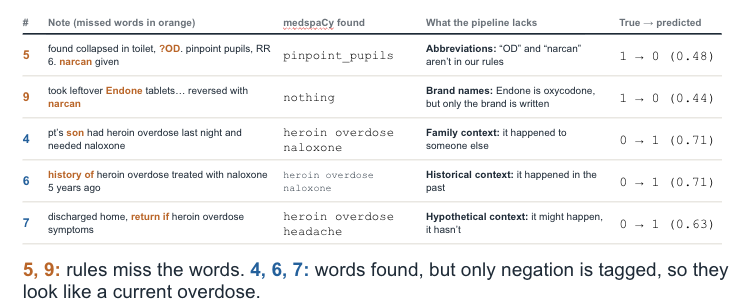

- **Notes 4, 6 and 7 (not enough context):** our model only marks negation. "pt's son had heroin overdose", "history of heroin overdose 5 years ago" and "return if heroin overdose symptoms" all look like a current overdose, so they are predicted 1. Negation alone is not enough: note 2 ("denies heroin or opioid use") is correctly predicted 0.
- **Notes 5 and 9 (abbreviations and brand names):** "?OD", "narcan" and "Endone" are not in our target rules, so medspaCy finds little or nothing. The model cannot use words it never sees.

#### Limitations of this exercise (vs real-world data)

- **Tiny dataset:** 20 notes here; real projects need hundreds to thousands.
- **Proper evaluation:** model performance is often evaluated using metrics such as a classification matrix, accuracy, sensitivity, precision, and F1-score. These measures provide model strength and error patterns, which can help perform comparison with other models.
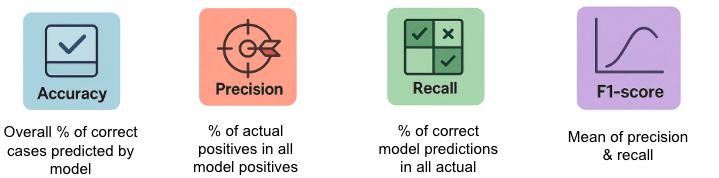
- **Data splits:** e.g. 70:15:15 train / validation / test, often with cross-validation to prevent *overfitting*.
- **Rules limit the model:** The model only extracts entities matched by explicit rules - missing rules = missing data. Iterative rule adjustments and fine-tuning are required to adapt to your specific research question.
- **Pretrained models:** Most recent real-world workflows start with pretrained model that already understands domain vocabulary, rather than building rule sets or models from scratch.

## Advanced Exercise

We only used negation. Other context flags (uncertain, historical, family) could be added the same way. Add other negation

In [ ]:
# In step 1 we built a function to help with entity extraction
def get_entities_adv(text):
    doc = nlp_med(text)
    words = []
    for ent in doc.ents:
        term = ent.text.lower().replace(" ", "_").replace("-", "_")   # Join words
        if ent._.is_negated:
            term = "neg_" + term   # Mark negation
        # Add your code here
        if ent._.is_xxxxxxx:
            term = "___" + term   # Mark uncertainty
        words.append(term)
    return " ".join(words)

After we make changes to the get_entities() function, we need to redo the exercise by annotating the notes with the updated function.

In [ ]:
# In step 1 we built a function to help with entity extraction
def get_entities_adv(text):
    doc = nlp_med(text)
    words = []
    for ent in doc.ents:
        term = ent.text.lower().replace(" ", "_").replace("-", "_")   # Join words
        if ent._.is_negated:
            term = "neg_" + term   # Mark negation
        if ent._.is_uncertain:
            term = "unc_" + term   # Mark uncertainty
        if ent._.is_hypothetical:
            term = "hyp_" + term   # Mark hypothetical
        if ent._.is_historical:
            term = "hist_" + term  # Mark historical
        if ent._.is_family:
            term = "fam_" + term   # Mark family history
        words.append(term)
    return " ".join(words)

In [ ]:
# Apply the updated get_entities function to our notes
df["adv_entities"] = df["note"].apply(get_entities_adv)
print("DataFrame with advanced entities:")
display(df.head())

In [ ]:
# Re-vectorize the text with the updated entities
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df["adv_entities"])

# Re-train the model with updated TF-IDF features and re-predict
adv_model = LogisticRegression()
adv_model.fit(X_tfidf, df["opioid_case"])

# Use the new notes (same as before)
# Re-extract entities using the updated get_entities_adv function
new_notes["adv_entities"] = new_notes["note"].apply(get_entities_adv)

# Convert to numbers using the re-fitted TFIDF vectorizer
X_new = tfidf.transform(new_notes["adv_entities"])

# Predict with the re-trained model
new_notes["predicted"] = adv_model.predict(X_new)
new_notes["probability"] = adv_model.predict_proba(X_new)[:, 1].round(2)

print("\nUpdated predictions for new notes:")
display(new_notes)

### Discussion

- Why did the predictions change after adding more context?
- What is the threshold that currently decides whether the note is related to opioid or not? What do you think will happen when we adjust this?
- How can we further evaluate the performance of this model? (We use these [metrics](https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall))

Thanks for your time and attention on this lab! Hope you had a good time and learnt some important concepts about NLP and `medspaCy`. Feel free to explore further and apply these techniques to your own clinical text data.